# XGBoost tuning on the winning approach

Uses the setup chosen in `02_compare_preprocessing.ipynb` (read from `results/best_setup.json`): approach C,
20% stratified test part, 10-fold stratified CV, outliers removed from the training data, class weights.

All tuning is evaluated with **CV on the training part**. The test part is used **once**, for the final model at the end.

## 1. Load the winning dataset and split

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from optuna.samplers import TPESampler
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import label_binarize

from common import (CLASS_LABELS, RANDOM_STATE, RESULTS_DIR, compute_scores, cross_validate, fit_model,
                    load_processed, split_features_target)

setup = json.loads((RESULTS_DIR / "best_setup.json").read_text())
FIT_OPTIONS = {"remove_outliers": setup["remove_outliers"], "balance": setup["balance"]}
setup

{'approach': 'C',
 'dataset': 'C_feature_engineering',
 'test_size': 0.2,
 'stratified': True,
 'k': 10,
 'remove_outliers': True,
 'balance': 'class_weight',
 'baseline_cv_f1': 0.7489}

In [2]:
X, y = split_features_target(load_processed(setup["dataset"]))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=setup["test_size"], stratify=y if setup["stratified"] else None, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=setup["k"], shuffle=True, random_state=RANDOM_STATE)

print("Training part:", X_train.shape, "| Test part:", X_test.shape)

Training part: (2344, 208) | Test part: (586, 208)


Same split and folds as in `02` (same `random_state`), so the default model below reproduces the baseline from `02`.

In [3]:
def make_model(**params):
    return xgb.XGBClassifier(enable_categorical=True, random_state=RANDOM_STATE, n_jobs=-1, **params)


def cv_scores(**params):
    folds = cross_validate(lambda: make_model(**params), X_train, y_train, cv, **FIT_OPTIONS)
    return {"train_f1": folds["train_f1"].mean(), "cv_f1": folds["val_f1"].mean(), "cv_f1_std": folds["val_f1"].std()}


baseline = cv_scores()
print(f"Default model: train macro-F1 {baseline['train_f1']:.3f} | CV macro-F1 {baseline['cv_f1']:.3f} ± {baseline['cv_f1_std']:.3f}")

Default model: train macro-F1 0.998 | CV macro-F1 0.749 ± 0.032


## 2. Manual hyperparameter experiments

Starting from the default model, **one hyperparameter is changed at a time** while all others keep their default value.
Comparing the training and CV macro-F1 for each value shows the bias-variance trade-off:
- both scores low → the model is too simple (**high bias**, underfitting),
- training score much higher than CV score → the model memorises the training data (**high variance**, overfitting).

| Hyperparameter | Default | What it controls | Higher value → |
|---|---|---|---|
| `max_depth` | 6 | maximum depth of each tree | more complex trees → more variance |
| `learning_rate` | 0.3 | how much each new tree corrects the previous ones | faster learning, more variance |
| `n_estimators` | 100 | number of trees | more corrections → more variance |
| `min_child_weight` | 1 | minimum (weighted) amount of data in a leaf | fewer small, specific leaves → less variance |
| `subsample` | 1.0 | share of houses each tree is trained on | less randomness → more variance |
| `colsample_bytree` | 1.0 | share of features each tree can use | less randomness → more variance |
| `reg_lambda` | 1 | L2 penalty on the leaf values | smaller leaf values → less variance |
| `gamma` | 0 | minimum loss reduction required for a split | fewer splits → less variance |

In [4]:
EXPERIMENTS = {
    "max_depth": [2, 3, 4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.1, 0.3, 0.6],
    "n_estimators": [50, 100, 200, 400, 800],
    "min_child_weight": [1, 3, 5, 10, 20],
    "subsample": [0.5, 0.7, 0.9, 1.0],
    "colsample_bytree": [0.3, 0.5, 0.7, 1.0],
    "reg_lambda": [0, 1, 5, 20, 50],
    "gamma": [0, 0.5, 1, 2, 5],
}

RERUN = False
MANUAL_PATH = RESULTS_DIR / "manual_tuning.csv"

if RERUN or not MANUAL_PATH.exists():
    rows = []
    for param, values in EXPERIMENTS.items():
        for value in values:
            rows.append({"param": param, "value": value, **cv_scores(**{param: value})})
            print(f"{param} = {value}: CV macro-F1 {rows[-1]['cv_f1']:.3f}")
    manual = pd.DataFrame(rows)
    manual.to_csv(MANUAL_PATH, index=False)
else:
    manual = pd.read_csv(MANUAL_PATH)

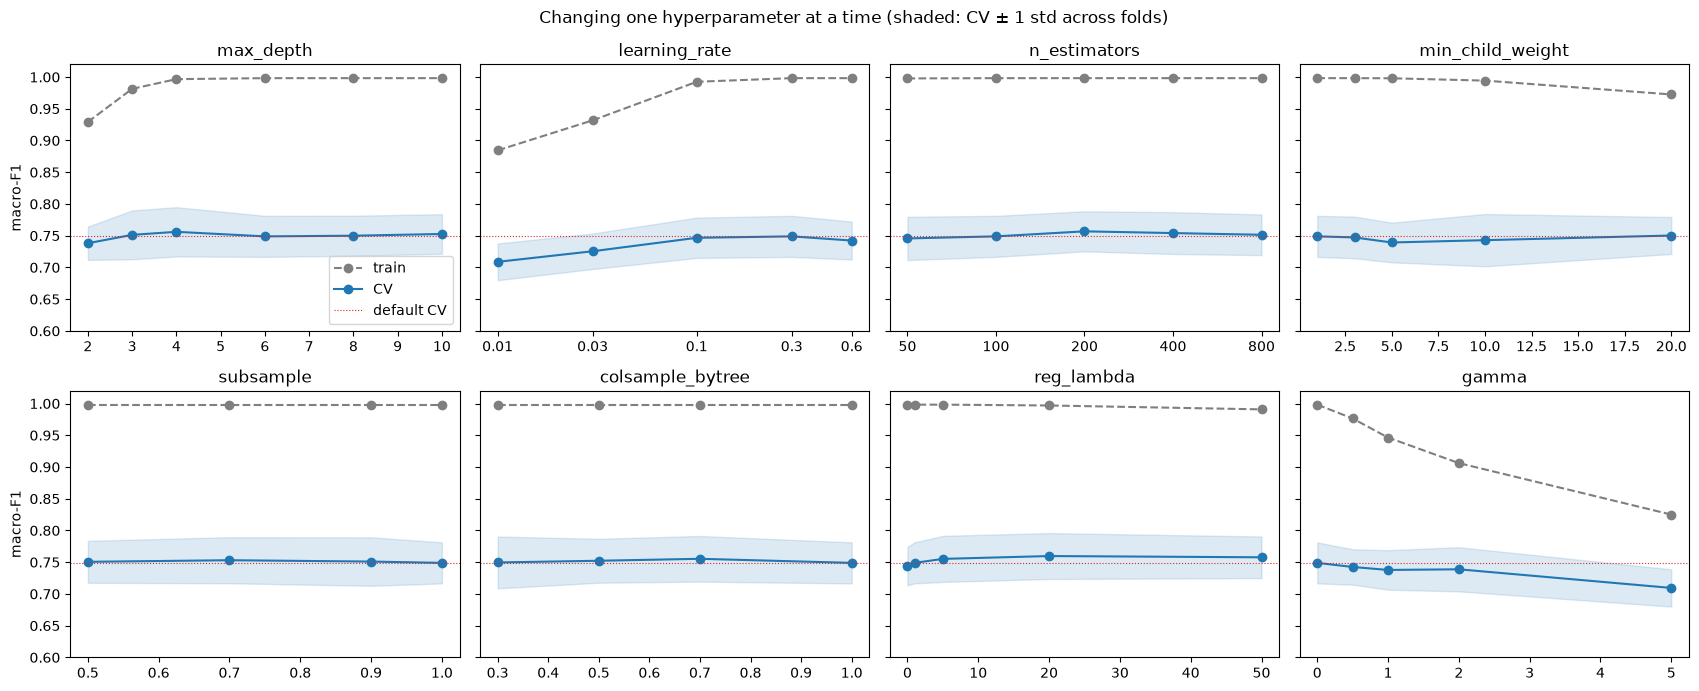

In [5]:
LOG_SCALE = {"learning_rate", "n_estimators"}

fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharey=True)
for ax, param in zip(axes.flat, EXPERIMENTS):
    r = manual[manual["param"] == param]
    ax.plot(r["value"], r["train_f1"], "o--", color="tab:gray", label="train")
    ax.plot(r["value"], r["cv_f1"], "o-", color="tab:blue", label="CV")
    ax.fill_between(r["value"], r["cv_f1"] - r["cv_f1_std"], r["cv_f1"] + r["cv_f1_std"], color="tab:blue", alpha=0.15)
    ax.axhline(baseline["cv_f1"], color="tab:red", lw=0.8, ls=":", label="default CV")
    if param in LOG_SCALE:
        ax.set_xscale("log")
        ax.minorticks_off()
        ax.set_xticks(r["value"], labels=[f"{v:g}" for v in r["value"]])
    ax.set_title(param); ax.set_ylim(0.6, 1.02)
axes[0, 0].legend(); axes[0, 0].set_ylabel("macro-F1"); axes[1, 0].set_ylabel("macro-F1")
fig.suptitle("Changing one hyperparameter at a time (shaded: CV ± 1 std across folds)")
fig.tight_layout()
plt.show()

In [6]:
manual["gap"] = manual["train_f1"] - manual["cv_f1"]
best_per_param = manual.loc[manual.groupby("param", sort=False)["cv_f1"].idxmax()].set_index("param")
best_per_param["change vs default"] = best_per_param["cv_f1"] - baseline["cv_f1"]
best_per_param.round(4)

,value,train_f1,cv_f1,cv_f1_std,gap,change vs default
param,,,,,,
max_depth,4.0,0.9967,0.7561,0.0389,0.2406,0.0072
learning_rate,0.3,0.9982,0.7489,0.0324,0.2493,0.0000
n_estimators,200.0,0.9982,0.7569,0.0316,0.2414,0.0079
min_child_weight,20.0,0.9726,0.7503,0.0291,0.2223,0.0014
subsample,0.7,0.9982,0.7531,0.0363,0.2451,0.0042
colsample_bytree,0.7,0.9982,0.7553,0.0360,0.2429,0.0064
reg_lambda,20.0,0.9969,0.7597,0.0362,0.2372,0.0108
gamma,0.0,0.9982,0.7489,0.0324,0.2493,0.0000


**Interpretation — one hyperparameter at a time**
- **The training macro-F1 stays at ≈ 1.0 for almost every value.** It only drops for settings that make the model clearly
  weaker (`gamma` ≥ 1, `learning_rate` ≤ 0.03, `max_depth` = 2) — and then the CV score drops too. Reducing variance this way
  turns into **high bias**: e.g. `gamma` = 5 lowers the training score to 0.83 and the CV score to 0.71.
- **The CV score stays around 0.74–0.76** whatever we change. Part of the train–CV gap is not overfitting that tuning can remove:
  the classes cut a *continuous* price into bins, so a house at 178,000 (class 3) and one at 182,000 (class 4) are almost
  identical — no model can separate them reliably.
- **Small improvements** come from regularisation and randomness: `reg_lambda` = 20 (+0.011), `n_estimators` = 200 (+0.008),
  `max_depth` = 4 (+0.007), `colsample_bytree` = 0.7 (+0.006), `subsample` = 0.7 (+0.004).
  These are about the size of the uncertainty of a 10-fold mean (fold std 0.03 / √10 ≈ 0.01), so single results should not be over-interpreted.
- **`learning_rate` cannot be judged alone:** with only 100 trees, a small learning rate stops before the model has learned
  enough (training F1 0.88 at 0.01 → underfitting). The next experiment shows the interaction with `n_estimators`.
- `min_child_weight` shows no clear trend; with class weights, the weight of a leaf is no longer just a count of houses.

### 2.1 Interaction: learning rate × number of trees
A smaller learning rate makes each tree correct less, so more trees are needed to reach the same fit.

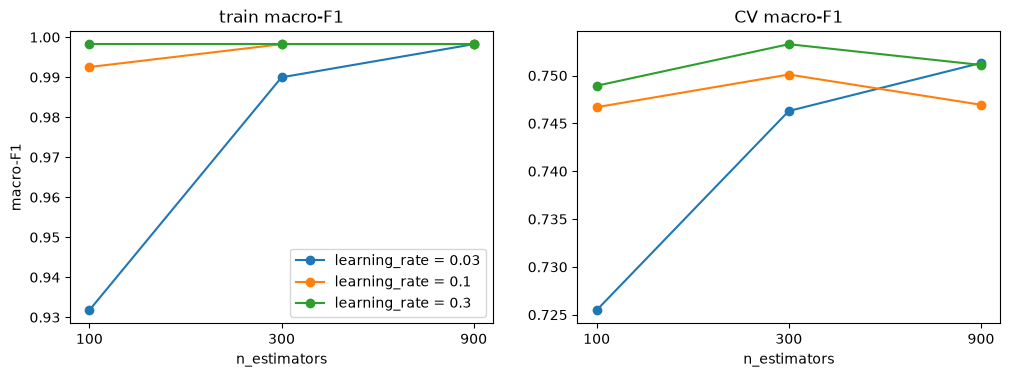

n_estimators,100,300,900
learning_rate,,,
0.03,0.7255,0.7463,0.7513
0.10,0.7467,0.7501,0.7469
0.30,0.7489,0.7533,0.7511


In [7]:
INTERACTION_PATH = RESULTS_DIR / "manual_tuning_lr_trees.csv"

if RERUN or not INTERACTION_PATH.exists():
    rows = [{"learning_rate": lr, "n_estimators": n, **cv_scores(learning_rate=lr, n_estimators=n)}
            for lr in [0.03, 0.1, 0.3] for n in [100, 300, 900]]
    interaction = pd.DataFrame(rows)
    interaction.to_csv(INTERACTION_PATH, index=False)
else:
    interaction = pd.read_csv(INTERACTION_PATH)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, title in [(axes[0], "train_f1", "train macro-F1"), (axes[1], "cv_f1", "CV macro-F1")]:
    for lr, r in interaction.groupby("learning_rate"):
        ax.plot(r["n_estimators"], r[metric], "o-", label=f"learning_rate = {lr}")
    ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks([100, 300, 900], labels=["100", "300", "900"])
    ax.set_xlabel("n_estimators"); ax.set_title(title)
axes[0].legend(); axes[0].set_ylabel("macro-F1")
plt.show()
interaction.pivot_table(index="learning_rate", columns="n_estimators", values="cv_f1").round(4)

**Interpretation — learning rate × trees**
- With `learning_rate` = 0.03, 100 trees are clearly not enough (training F1 0.93, CV 0.73 → underfitting). With 300 and
  900 trees it reaches the same level as the faster learning rates (CV 0.746 → 0.751).
- With `learning_rate` = 0.3, the training data is fitted almost perfectly after only 100 trees; more trees change little.
- All combinations end up at **CV ≈ 0.75**: the learning rate mainly changes *how many trees are needed*, not how good the model
  can become. A small learning rate with many trees is usually a bit more robust, but slower to train.

### 2.2 Combining the best values
Each value above was found with all other hyperparameters at their defaults. Hyperparameters interact (e.g. a lower learning rate
needs more trees), so combining the individual best values does not necessarily add up their improvements:

In [8]:
MANUAL_PARAMS = {"max_depth": 4, "n_estimators": 200, "subsample": 0.7, "colsample_bytree": 0.7, "reg_lambda": 20}

manual_combined = cv_scores(**MANUAL_PARAMS)
pd.DataFrame({"default": baseline, "manual combination": manual_combined}).T.round(4)

,train_f1,cv_f1,cv_f1_std
default,0.9982,0.7489,0.0324
manual combination,0.9952,0.7510,0.0403


**Interpretation — combination**
- The combination reaches a CV macro-F1 of **0.751** — barely above the default (0.749) and *below* `reg_lambda` = 20 alone (0.760).
- Two reasons: the hyperparameters **interact** (e.g. shallower trees + strong L2 penalty + subsampling together regularise
  too much), and some of the individual gains were **noise** of the size of the CV uncertainty (≈ 0.01).
- Changing one hyperparameter at a time is good for *understanding* what each one does, but it cannot find the best
  *combination*. This is why the next step searches all hyperparameters together with Optuna.

## 3. Optuna (TPESampler) with SQLite storage

Optuna searches **all hyperparameters together**. The **Tree-structured Parzen Estimator (TPE)** is a form of Bayesian optimisation:
- the first trials are random (here 10) to get an overview of the search space,
- afterwards the completed trials are split into "good" (best ≈ 10–25%) and "bad",
- TPE models the distribution of hyperparameter values in each group — l(x) for the good trials, g(x) for the bad ones —
  and proposes the next values where the ratio **l(x) / g(x)** is highest, i.e. values that are common among good trials and
  rare among bad ones.

So each new trial uses what was learned from all earlier trials, instead of sampling blindly like a grid or random search.

**Objective:** the same 10-fold CV macro-F1 as before (outliers removed, class weights) — the test part is not used.

**Search space** (based on the manual experiments):

| Hyperparameter | Range | Scale |
|---|---|---|
| `max_depth` | 2 – 10 | integer |
| `learning_rate` | 0.01 – 0.3 | log |
| `n_estimators` | 100 – 800 | integer, step 50 |
| `min_child_weight` | 1 – 20 | log |
| `subsample` | 0.5 – 1.0 | linear |
| `colsample_bytree` | 0.5 – 1.0 | linear |
| `reg_lambda` (L2) | 0.001 – 50 | log |
| `reg_alpha` (L1) | 0.001 – 50 | log |
| `gamma` | 0 – 2 | linear |

A log scale is used for parameters where the *ratio* matters more than the difference (0.01 → 0.02 is as big a step as 0.1 → 0.2).

In [9]:
def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 20, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 50, log=True),
        "gamma": trial.suggest_float("gamma", 0, 2),
    }
    folds = cross_validate(lambda: make_model(**params), X_train, y_train, cv, **FIT_OPTIONS)
    trial.set_user_attr("train_f1", folds["train_f1"].mean())
    trial.set_user_attr("cv_f1_std", folds["val_f1"].std())
    return folds["val_f1"].mean()

The study is stored in a **SQLite database** (`results/optuna_xgboost.db`): every finished trial is saved immediately, so an
interrupted run can be resumed, and the notebook can be re-run without repeating the search. Only the trials still missing
from `N_TRIALS` are run.

In [10]:
N_TRIALS = 100
STORAGE = f"sqlite:///{RESULTS_DIR / 'optuna_xgboost.db'}"

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(study_name="xgboost_approach_C", storage=STORAGE, direction="maximize",
                            sampler=TPESampler(n_startup_trials=10, seed=RANDOM_STATE), load_if_exists=True)


def print_progress(study, trial):
    if (trial.number + 1) % 10 == 0:
        print(f"trial {trial.number + 1}: CV macro-F1 {trial.value:.4f} | best so far {study.best_value:.4f}")


finished = len(study.get_trials(states=[optuna.trial.TrialState.COMPLETE]))
if finished < N_TRIALS:
    study.optimize(objective, n_trials=N_TRIALS - finished, callbacks=[print_progress])

print(f"{len(study.trials)} trials | best CV macro-F1 {study.best_value:.4f} (trial {study.best_trial.number})")

100 trials | best CV macro-F1 0.7730 (trial 64)


In [11]:
best_params = study.best_params
comparison = pd.DataFrame({
    "default": {**baseline},
    "manual combination": {**manual_combined},
    "Optuna best": {"train_f1": study.best_trial.user_attrs["train_f1"], "cv_f1": study.best_value,
                    "cv_f1_std": study.best_trial.user_attrs["cv_f1_std"]},
}).T
display(comparison.round(4))
pd.Series(best_params).to_frame("best value")

,train_f1,cv_f1,cv_f1_std
default,0.9982,0.7489,0.0324
manual combination,0.9952,0.7510,0.0403
Optuna best,0.9966,0.7730,0.0341


,best value
max_depth,7.000000
learning_rate,0.082080
n_estimators,400.000000
min_child_weight,1.705851
subsample,0.678552
colsample_bytree,0.576507
reg_lambda,0.002129
reg_alpha,0.078369
gamma,0.205715


## 4. Visualizations of the optimization process

The plots are interactive (plotly): hover over a point to see the trial's hyperparameters. They are displayed in Jupyter and
VS Code; static viewers such as GitHub do not show plotly output.

**Optimization history** — CV macro-F1 of every trial and the best value so far.

In [12]:
optuna.visualization.plot_optimization_history(study)

**Hyperparameter importances** — how much of the variation in the CV score each hyperparameter explains
(estimated with fANOVA from the completed trials).

In [13]:
optuna.visualization.plot_param_importances(study)

**Slice plot** — CV score against each hyperparameter value; darker points are later trials. Where TPE concentrates its
trials shows which regions it learned to prefer.

In [14]:
optuna.visualization.plot_slice(study)

**Parallel coordinates** — each line is one trial; good trials (dark) show which *combinations* work well together.

In [15]:
optuna.visualization.plot_parallel_coordinate(study)

**Contour plot** of the two most important hyperparameters — how they interact.

In [16]:
top_two = list(optuna.importance.get_param_importances(study))[:2]
optuna.visualization.plot_contour(study, params=top_two)

**Bias-variance across trials** — training vs. CV macro-F1 of every trial.

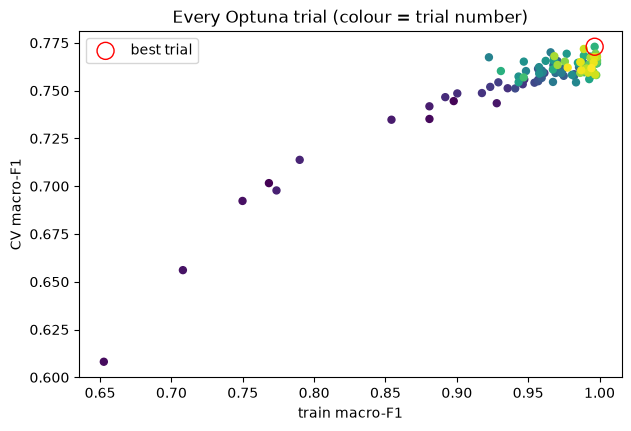

In [17]:
trials = study.trials_dataframe(attrs=("number", "value", "user_attrs"))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(trials["user_attrs_train_f1"], trials["value"], c=trials["number"], cmap="viridis", s=25)
ax.scatter(study.best_trial.user_attrs["train_f1"], study.best_value, s=150, facecolors="none", edgecolors="red", label="best trial")
ax.set_xlabel("train macro-F1"); ax.set_ylabel("CV macro-F1"); ax.legend()
ax.set_title("Every Optuna trial (colour = trial number)")
plt.show()

**Interpretation — Optuna**
- **Best CV macro-F1: 0.773** (trial 64) — **+0.024** over the default model (0.749) and +0.013 over the best manual change
  (`reg_lambda` = 20, 0.760). Searching all hyperparameters together clearly beats changing them one at a time.
- **TPE learns:** the 10 random start-up trials average 0.706, the last 50 trials 0.763. The best value improves quickly up to
  ≈ trial 30 (0.768) and only slowly afterwards (0.773 at trial 64, unchanged until 100) — more trials would bring little.
- **A stable region, not a lucky trial:** the 10 best trials are all within 0.005 of each other and share similar values —
  `max_depth` 7–9, `learning_rate` ≈ 0.07–0.1, 350–450 trees, `min_child_weight` ≈ 2, row and column subsampling ≈ 0.6–0.7.
- **Most important hyperparameters:** `learning_rate`, then `colsample_bytree` and `n_estimators` — consistent with the
  manual experiment, where the learning rate only worked together with enough trees.
- **Regularisation by randomness instead of L2:** the manual experiments favoured `reg_lambda` = 20, but Optuna chooses an
  almost zero L2 penalty (≈ 0.002). In combination with row/column subsampling and a small `gamma`, a strong L2 penalty is no
  longer needed — another example of hyperparameters interacting.
- **Bias-variance:** the scatter plot shows the two regimes. Early trials on the left fit the training data poorly and score
  low on CV (**high bias**). The best trials fit the training data almost perfectly (train ≈ 0.99) *and* score highest on CV:
  with many small learning steps and subsampling, the remaining train–CV gap is mostly the irreducible noise at the class
  boundaries, not harmful overfitting.
- **Caveat:** the best of 100 trials on the same folds is slightly optimistic — some of its lead over trial 2–10 is luck.
  The test part, used once in section 5, gives the unbiased estimate.

The best hyperparameters are saved to `results/best_params.json`.

In [18]:
(RESULTS_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2))

306

## 5. Final model: test-set metrics

The final model uses the best Optuna hyperparameters and is trained on the **whole training part** (outliers removed,
class weights). The test part — 586 houses never used for any decision so far — is evaluated **once**.

The default model is trained and tested the same way for comparison. This is only reporting: no decision is based on the test scores.

In [19]:
CLASS_NAMES = [f"{c}: {label}" for c, label in CLASS_LABELS.items()]

final_model = fit_model(make_model(**best_params), X_train, y_train, **FIT_OPTIONS)
default_model = fit_model(make_model(), X_train, y_train, **FIT_OPTIONS)

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

test_results = pd.DataFrame({
    "default (test)": compute_scores(y_test, default_model.predict(X_test)),
    "tuned (test)": compute_scores(y_test, y_pred),
    "tuned (CV)": {m: np.nan for m in ["accuracy", "precision", "recall"]} | {"f1": study.best_value},
}).T
test_results.round(4)

,accuracy,precision,recall,f1
default (test),0.7782,0.7653,0.7693,0.7659
tuned (test),0.7747,0.7576,0.7687,0.7626
tuned (CV),NaN,NaN,NaN,0.7730


In [20]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

                precision    recall  f1-score   support

     1: < 100k      0.723     0.708     0.716        48
2: 100k - 130k      0.673     0.745     0.707       102
3: 130k - 180k      0.815     0.787     0.801       207
4: 180k - 250k      0.795     0.766     0.781       137
5: 250k - 400k      0.825     0.835     0.830        79
    6: >= 400k      0.714     0.769     0.741        13

      accuracy                          0.775       586
     macro avg      0.758     0.769     0.763       586
  weighted avg      0.777     0.775     0.775       586



**Is the difference between the tuned and the default model on the test part real?** A paired **bootstrap** answers this:
draw 2000 random samples (with replacement) of the 586 test houses, compute the macro-F1 difference of the two models on each
sample, and look at the spread. If the 95% interval contains 0, the test part cannot tell the models apart.

In [21]:
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr, y_pred_default = y_test.to_numpy(), default_model.predict(X_test)
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    diffs.append(f1_score(y_test_arr[idx], y_pred[idx], average="macro")
                 - f1_score(y_test_arr[idx], y_pred_default[idx], average="macro"))
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"Macro-F1 difference tuned - default: {np.mean(diffs):+.4f}, 95% interval [{low:+.4f}, {high:+.4f}]")

Macro-F1 difference tuned - default: -0.0035, 95% interval [-0.0224, +0.0138]


**Interpretation — test set**
- **Tuned model on the test part: macro-F1 0.763, accuracy 0.775** — close to its CV estimate (0.773), so the CV results were
  a reliable guide and the model generalises as expected.
- **The default model scores about the same on the test part (0.766).** The bootstrap shows why this is not a contradiction:
  the difference is −0.004 with a 95% interval of about [−0.022, +0.014] — the 586 test houses (only 13 in class 6) are simply too
  few to separate two models that differ by ≈ 0.02. The CV comparison (10 folds on 2344 houses) is the more reliable evidence
  that tuning helps (+0.024), although part of that gain is the optimism of picking the best of 100 trials.
- We do **not** switch back to the default model because of the test score — choosing a model on the test part would turn it into
  a validation set and its score would no longer be an unbiased estimate.
- **Per class:** the best F1 is reached for class 5 (0.83) and class 3 (0.80), the lowest for classes 1 and 2 (0.72 / 0.71).
  Class 2 covers a narrow price range (100k–130k) with neighbours on both sides, so many of its houses lie close to a boundary.
  Class 6 reaches recall 0.77 (10 of 13 houses), helped by the class weights.

## 6. Confusion matrix, ROC curve, precision-recall curve

### 6.1 Confusion matrix
Rows: true class, columns: predicted class. Left: number of houses; right: share of each true class (rows sum to 1, the diagonal is the recall).

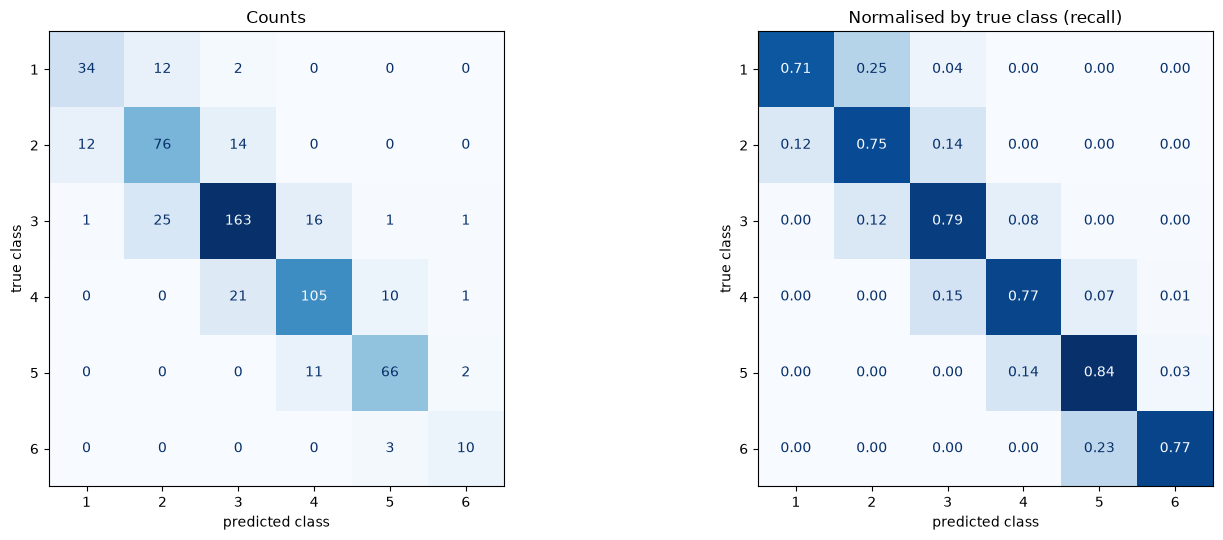

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, normalize, title in [(axes[0], None, "Counts"), (axes[1], "true", "Normalised by true class (recall)")]:
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=list(CLASS_LABELS), normalize=normalize,
                                            values_format=".2f" if normalize else "d", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title); ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
plt.tight_layout()
plt.show()

### 6.2 ROC and precision-recall curves (one-vs-rest)
For a multiclass model, each class gets its own curve: "this class" vs. "all other classes", using the predicted probability of that class.
- **ROC curve**: true-positive rate vs. false-positive rate for every threshold; **AUC** = 1 is perfect, 0.5 is random guessing.
- **Precision-recall curve**: more informative for small classes, because the many true negatives of the other classes do not
  make it look good. **Average precision (AP)** summarises it; random guessing gives AP = the class's share of houses.

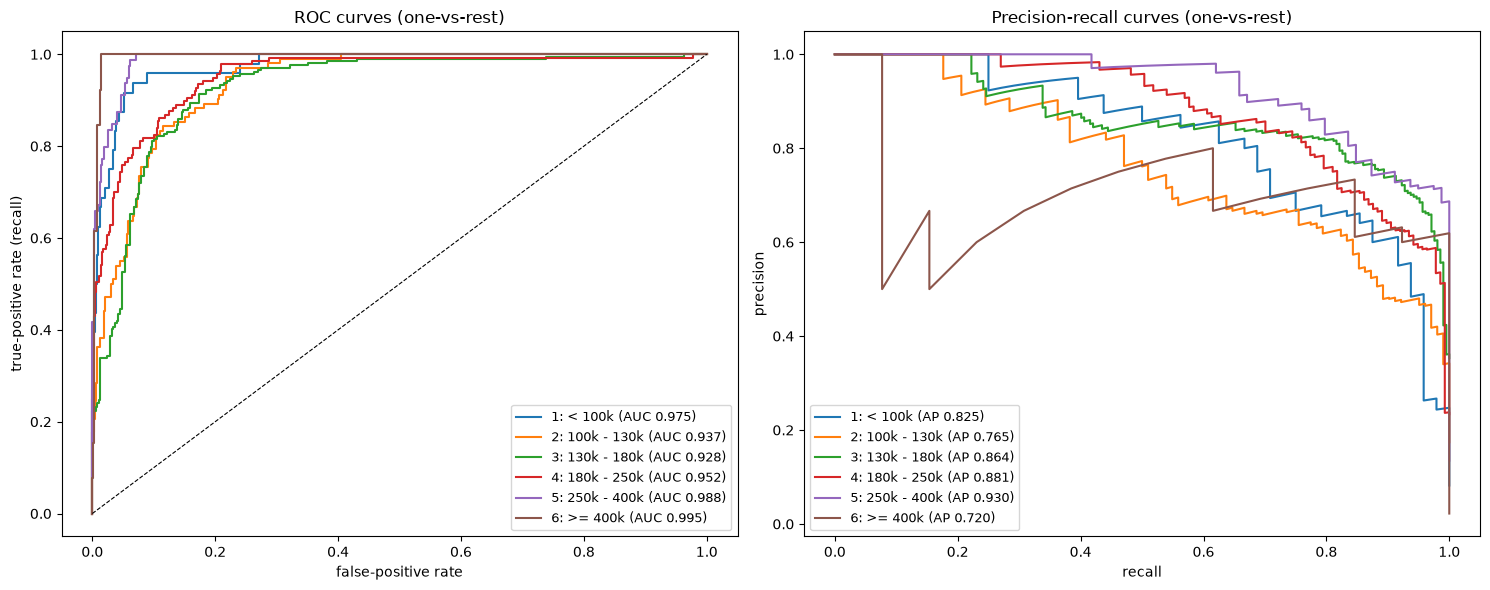

Macro ROC-AUC: 0.962
Macro average precision: 0.831


In [23]:
y_test_bin = label_binarize(y_test, classes=range(6))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for c, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], y_proba[:, c])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test_bin[:, c], y_proba[:, c]):.3f})")
    precision, recall, _ = precision_recall_curve(y_test_bin[:, c], y_proba[:, c])
    axes[1].plot(recall, precision, label=f"{name} (AP {average_precision_score(y_test_bin[:, c], y_proba[:, c]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="false-positive rate", ylabel="true-positive rate (recall)", title="ROC curves (one-vs-rest)")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curves (one-vs-rest)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
plt.tight_layout()
plt.show()

print(f"Macro ROC-AUC: {roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'):.3f}")
print(f"Macro average precision: {average_precision_score(y_test_bin, y_proba, average='macro'):.3f}")

**Interpretation — confusion matrix and curves**
- **All errors are between neighbouring classes** (e.g. 25 class-3 houses predicted as class 2, 21 class-4 houses as class 3);
  only 6 of the 586 houses are off by more than one class. The model has learned the price *order* — it struggles mainly where
  prices are close to a class boundary.
- **ROC-AUC is high for every class (0.93–0.995, macro 0.962)**: the probabilities rank houses very well. The middle classes
  (2, 3) have the lowest AUC because they have neighbours on both sides.
- **The precision-recall curves are more critical**: class 6 has the highest ROC-AUC (0.995) but the lowest average precision
  (0.72). With only 13 positives, a few false positives cost a lot of precision, and the many easy negatives that make the ROC
  curve look perfect do not count. This is why PR curves are the better view for small classes.

## 7. Thresholds for the best macro-F1

By default the model predicts the class with the **highest probability** (argmax). Every point of a class's precision-recall curve
corresponds to a different threshold on that class's probability; a lower threshold means higher recall but lower precision.

**Method:**
1. Get **out-of-fold probabilities** for the training part: in 10-fold CV each house is predicted by a model that did not see it.
   (The thresholds must not be chosen on the test part.)
2. For each class, pick the threshold on its precision-recall curve with the **highest F1** (one-vs-rest).
3. Combine them into one multiclass decision: predict the class with the highest **probability / threshold** ratio, so a class
   with a low threshold is favoured. With equal thresholds this is the normal argmax.
4. Compare macro-F1 with and without thresholds — first on the out-of-fold predictions, then **once** on the test part.

### 7.1 Best-F1 threshold per class (from the precision-recall curves)

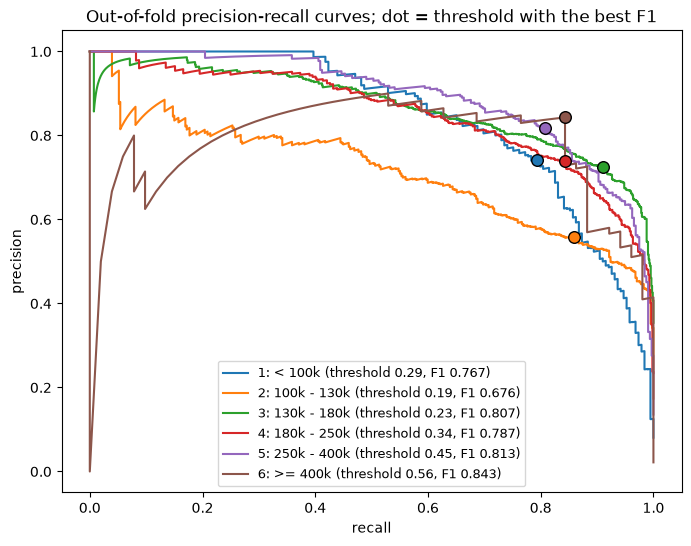

,threshold,one-vs-rest F1
1: < 100k,0.288,0.767
2: 100k - 130k,0.186,0.676
3: 130k - 180k,0.234,0.807
4: 180k - 250k,0.340,0.787
5: 250k - 400k,0.446,0.813
6: >= 400k,0.561,0.843


In [24]:
oof_proba = np.zeros((len(X_train), 6))
for train_idx, val_idx in cv.split(X_train, y_train):
    model = fit_model(make_model(**best_params), X_train.iloc[train_idx], y_train.iloc[train_idx], **FIT_OPTIONS)
    oof_proba[val_idx] = model.predict_proba(X_train.iloc[val_idx])

y_train_bin = label_binarize(y_train, classes=range(6))
thresholds, best_class_f1 = np.zeros(6), np.zeros(6)
fig, ax = plt.subplots(figsize=(8, 6))
for c, name in enumerate(CLASS_NAMES):
    precision, recall, thr = precision_recall_curve(y_train_bin[:, c], oof_proba[:, c])
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    best = np.argmax(f1[:-1])  # the last point of the curve has no threshold
    thresholds[c], best_class_f1[c] = thr[best], f1[best]
    line, = ax.plot(recall, precision, label=f"{name} (threshold {thr[best]:.2f}, F1 {f1[best]:.3f})")
    ax.scatter(recall[best], precision[best], color=line.get_color(), s=70, edgecolors="black", zorder=3)
ax.set(xlabel="recall", ylabel="precision", title="Out-of-fold precision-recall curves; dot = threshold with the best F1")
ax.legend(fontsize=9)
plt.show()

pd.DataFrame({"threshold": thresholds, "one-vs-rest F1": best_class_f1}, index=CLASS_NAMES).round(3)

In [25]:
def predict_with_thresholds(proba, thresholds):
    return np.argmax(proba / thresholds, axis=1)


threshold_results = pd.DataFrame({
    "argmax": {"out-of-fold (train)": f1_score(y_train, oof_proba.argmax(axis=1), average="macro"),
               "test": f1_score(y_test, y_proba.argmax(axis=1), average="macro")},
    "best-F1 thresholds": {"out-of-fold (train)": f1_score(y_train, predict_with_thresholds(oof_proba, thresholds), average="macro"),
                           "test": f1_score(y_test, predict_with_thresholds(y_proba, thresholds), average="macro")},
})
threshold_results["change"] = threshold_results["best-F1 thresholds"] - threshold_results["argmax"]
threshold_results.round(4)

,argmax,best-F1 thresholds,change
out-of-fold (train),0.7718,0.7680,-0.0039
test,0.7626,0.7604,-0.0022


### 7.2 Optimising macro-F1 directly
The thresholds in 7.1 maximise each class's F1 *on its own* — that is not the same as maximising the macro-F1 of the multiclass
decision. Here the 6 thresholds are tuned **together** to maximise macro-F1 on the out-of-fold predictions: one class at a time,
try 41 values between 0.3× and 3× and keep the best, and repeat this for all classes 3 times (coordinate ascent).

Tuning 6 numbers on the same predictions that are used to score them is optimistic, so an honest estimate is needed too:
the thresholds are tuned on 9 of 10 parts of the out-of-fold predictions and evaluated on the 10th (a nested CV).

In [26]:
SCALES = np.exp(np.linspace(np.log(0.3), np.log(3), 41))


def tune_thresholds(proba, y_true, rounds=3):
    t = np.ones(proba.shape[1])
    for _ in range(rounds):
        for c in range(len(t)):
            scores = []
            for scale in SCALES:
                candidate = t.copy()
                candidate[c] = 1 / scale
                scores.append(f1_score(y_true, predict_with_thresholds(proba, candidate), average="macro"))
            t[c] = 1 / SCALES[int(np.argmax(scores))]
    return t


joint_thresholds = tune_thresholds(oof_proba, y_train)

nested_gain = []
for tune_idx, eval_idx in StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE).split(oof_proba, y_train):
    t = tune_thresholds(oof_proba[tune_idx], y_train.iloc[tune_idx], rounds=2)
    y_eval = y_train.iloc[eval_idx]
    nested_gain.append(f1_score(y_eval, predict_with_thresholds(oof_proba[eval_idx], t), average="macro")
                       - f1_score(y_eval, oof_proba[eval_idx].argmax(axis=1), average="macro"))

threshold_results["jointly tuned"] = [
    f1_score(y_train, predict_with_thresholds(oof_proba, joint_thresholds), average="macro"),
    f1_score(y_test, predict_with_thresholds(y_proba, joint_thresholds), average="macro")]
print("Relative thresholds (lower = class favoured):", {c: round(float(t), 3) for c, t in zip(CLASS_LABELS, joint_thresholds)})
print(f"Nested-CV change vs. argmax: {np.mean(nested_gain):+.4f} ± {np.std(nested_gain):.4f}")
threshold_results.drop(columns="change").round(4)

Relative thresholds (lower = class favoured): {1: 1.183, 2: 1.183, 3: 0.995, 4: 0.704, 5: 0.79, 6: 0.995}
Nested-CV change vs. argmax: -0.0014 ± 0.0116


,argmax,best-F1 thresholds,jointly tuned
out-of-fold (train),0.7718,0.7680,0.7769
test,0.7626,0.7604,0.7620


**Interpretation — thresholds**
- **Per-class best-F1 thresholds (7.1) do not help** (−0.004 out-of-fold, −0.002 on test). Each threshold is optimal for its
  class *alone*; combined into one decision, the classes compete for the same houses and the optimum shifts.
- **Jointly tuned thresholds (7.2)** look better on the predictions they were tuned on (0.772 → 0.777), but the nested CV shows
  that this is overfitting: −0.001 ± 0.012 on unseen parts, and −0.001 on the test part.
- **Conclusion: the plain argmax is already (close to) the best macro-F1 decision.** The class weights have already shifted the
  probabilities in favour of the small classes, which is what threshold tuning would otherwise do. The final model keeps argmax.

## 8. First tree, best tree, feature importance (gain and split)

For 6 classes XGBoost builds **6 trees per boosting round** — one per class, each pushing the score of its class up or down.
With 400 rounds the final model has 2400 trees. Tree number *i* belongs to round *i* // 6 and class (*i* mod 6) + 1.

- **First tree:** tree 0 — round 1, class 1.
- **Best tree:** we define it as the tree with the **largest total gain** (sum of the loss reductions of all its splits),
  i.e. the single tree that improves the model the most.

The trees are rendered as zoomable SVG images.

In [27]:
booster = final_model.get_booster()
tree_table = booster.trees_to_dataframe()
splits = tree_table[tree_table["Feature"] != "Leaf"]

tree_stats = splits.groupby("Tree").agg(total_gain=("Gain", "sum"), splits=("Gain", "size"))
tree_stats["leaves"] = tree_table[tree_table["Feature"] == "Leaf"].groupby("Tree").size()
tree_stats["round"] = tree_stats.index // 6 + 1
tree_stats["class"] = tree_stats.index % 6 + 1

best_tree = int(tree_stats["total_gain"].idxmax())
tree_stats.loc[[0, best_tree]].assign(tree=["first tree", "best tree"]).set_index("tree")

,total_gain,splits,leaves,round,class
tree,,,,,
first tree,667.410643,37,38,1,1
best tree,755.059359,10,11,1,6


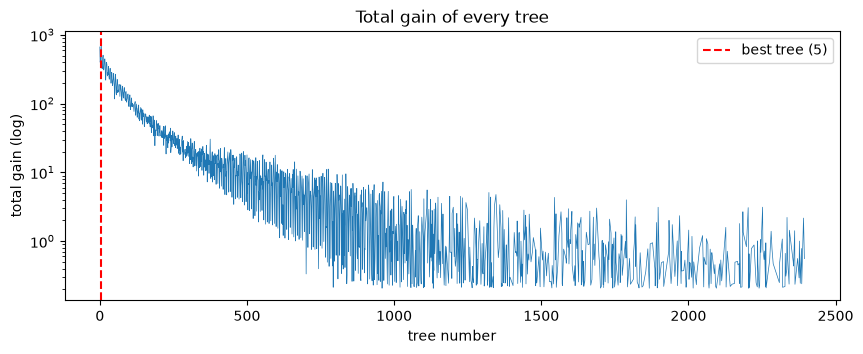

In [28]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tree_stats.index, tree_stats["total_gain"], lw=0.5)
ax.axvline(best_tree, color="red", ls="--", label=f"best tree ({best_tree})")
ax.set_yscale("log"); ax.set_xlabel("tree number"); ax.set_ylabel("total gain (log)")
ax.set_title("Total gain of every tree"); ax.legend()
plt.show()

### 8.1 First tree (tree 0 — round 1, class 1)

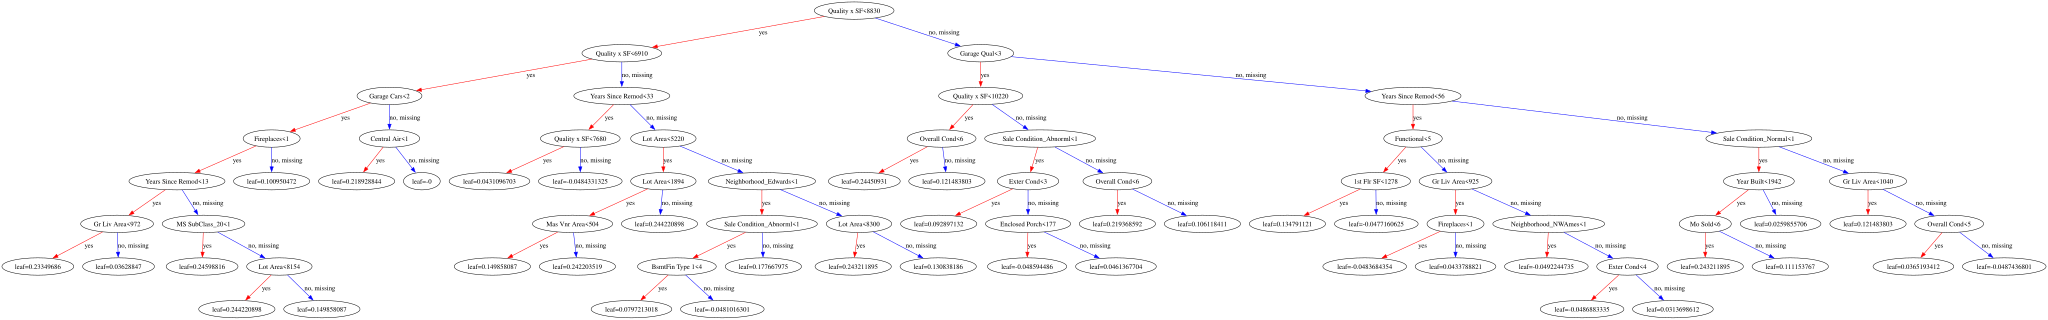

In [29]:
xgb.to_graphviz(final_model, tree_idx=0)

### 8.2 Best tree (largest total gain)

Tree 5: round 1, class 6


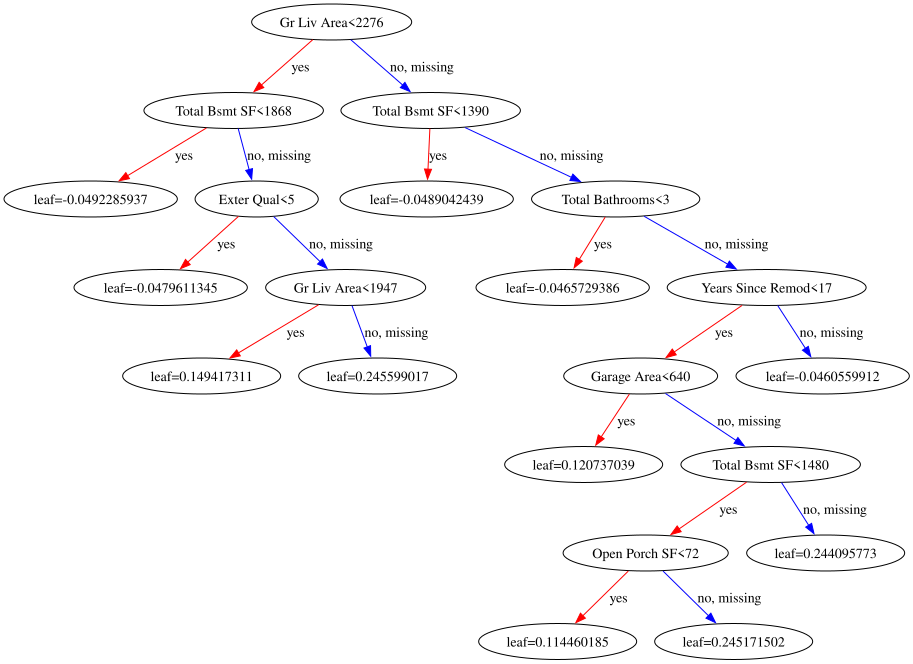

In [30]:
print(f"Tree {best_tree}: round {best_tree // 6 + 1}, class {best_tree % 6 + 1}")
xgb.to_graphviz(final_model, tree_idx=best_tree)

In [31]:
pd.DataFrame({tree: splits[splits["Tree"] == tree].groupby("Feature")["Gain"].sum().nlargest(5).round(1).index
              for tree in [0, best_tree]}).set_axis(["first tree: top features", "best tree: top features"], axis=1)

,first tree: top features,best tree: top features
0,Quality x SF,Gr Liv Area
1,Garage Qual,Total Bsmt SF
2,Years Since Remod,Exter Qual
3,Sale Condition_Abnorml,Total Bathrooms
4,Lot Area,Years Since Remod


**Interpretation — trees**
- **The first tree** (class 1, 37 splits) starts with `Quality x SF` < 8830 and `Garage Qual` — the cheapest houses are small,
  low-quality houses, often with a poor or no garage.
- **The best tree** is tree 5 — round 1, class 6 (≥ 400k). It has only 10 splits on size and quality (`Gr Liv Area`,
  `Total Bsmt SF`, `Exter Qual`), yet the largest total gain: a few splits on size separate the most expensive houses.
  Its gain is also amplified by the class weights: a class-6 house counts 7.8 times, a class-3 house 0.47 times.
- **Gain decreases quickly with the boosting rounds** (average per tree: 561 in round 1, 8 in round 100, 1 in round 400) — the
  10 best trees all come from rounds 1–3. The first trees learn the big structure; later trees only make small corrections,
  which is how boosting with a small learning rate works.

### 8.3 Feature importance: gain and split
- **Gain**: the average loss reduction of the splits that use a feature — *how useful* the feature is when it is used.
- **Split** (`weight` in XGBoost): how many times a feature is used for a split across all trees — *how often* it is used.
- **Total gain** (= gain × split) is shown in the table as a third view: the feature's total contribution to the model.

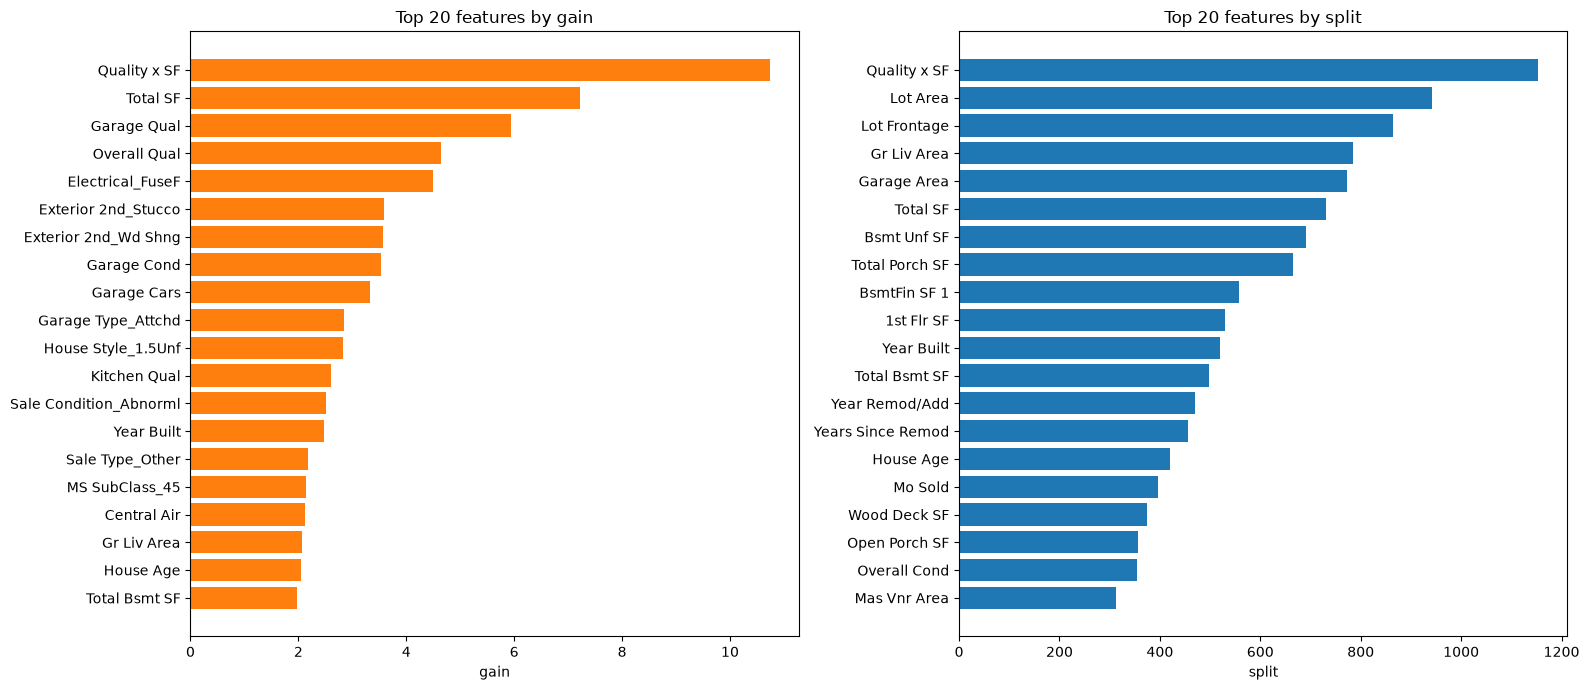

In [32]:
TOP = 20
importance = pd.DataFrame({
    "gain": pd.Series(booster.get_score(importance_type="gain")),
    "split": pd.Series(booster.get_score(importance_type="weight")),
    "total gain": pd.Series(booster.get_score(importance_type="total_gain")),
}).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, kind in zip(axes, ["gain", "split"]):
    top = importance[kind].nlargest(TOP)[::-1]
    ax.barh(top.index, top.values, color="tab:orange" if kind == "gain" else "tab:blue")
    ax.set_title(f"Top {TOP} features by {kind}"); ax.set_xlabel(kind)
plt.tight_layout()
plt.show()

In [33]:
for kind in ["gain", "split", "total gain"]:
    importance[f"{kind} rank"] = importance[kind].rank(ascending=False, method="min").astype(int)
importance.sort_values("gain rank").head(10).round(1)

,gain,split,total gain,gain rank,split rank,total gain rank
Quality x SF,10.7,1154.0,12392.4,1,1,1
Total SF,7.2,731.0,5274.4,2,6,2
Garage Qual,5.9,61.0,362.9,3,49,20
Overall Qual,4.6,211.0,980.1,4,25,8
Electrical_FuseF,4.5,3.0,13.5,5,151,109
Exterior 2nd_Stucco,3.6,1.0,3.6,6,164,149
Exterior 2nd_Wd Shng,3.6,2.0,7.1,7,156,134
Garage Cond,3.5,40.0,141.1,8,65,38
Garage Cars,3.3,104.0,345.2,9,36,22
Garage Type_Attchd,2.8,31.0,88.2,10,73,45


**Interpretation — feature importance**
- **`Quality x SF` is the most important feature by every measure** (gain, split and total gain), and `Total SF` is second by
  gain — the engineered features from approach C are what the model relies on most, confirming the choice of C in `02`.
- **Gain and split measure different things.** By split, continuous features with many possible split points dominate
  (`Lot Area`, `Lot Frontage`, `Garage Area`): they are used often for fine adjustments, each split with little gain.
  By gain, quality ratings (`Garage Qual`, `Overall Qual`) rank high: used less often, but each split matters more.
- **Average gain can be misleading for rare features:** `Electrical_FuseF` (3 splits) or `Exterior 2nd_Stucco` (1 split) are
  in the gain top 10 only because their few splits happened to be good. Total gain (gain × split) ranks them far lower and is the
  more robust summary.

In [34]:
final_metrics = {"cv_f1": round(study.best_value, 4),
                 **{f"test_{m}": round(v, 4) for m, v in test_results.loc["tuned (test)"].items()},
                 "test_f1_with_thresholds": round(float(threshold_results.loc["test", "jointly tuned"]), 4)}
(RESULTS_DIR / "final_metrics.json").write_text(json.dumps(final_metrics, indent=2))
final_metrics

{'cv_f1': 0.773,
 'test_accuracy': 0.7747,
 'test_precision': 0.7576,
 'test_recall': 0.7687,
 'test_f1': 0.7626,
 'test_f1_with_thresholds': 0.762}

## 9. Interpretation

| Step | Result |
|---|---|
| Default model (CV) | macro-F1 0.749 |
| Manual tuning, best single change (CV) | 0.760 (`reg_lambda` = 20) |
| Optuna, 100 trials (CV) | **0.773** |
| **Final model on the test part** | **macro-F1 0.763, accuracy 0.775**, macro ROC-AUC 0.962 |
| Thresholds for macro-F1 | no gain — argmax kept |

- **Bias-variance:** the default model already has low bias; its weakness is variance. Tuning reduced it with a lower learning
  rate, more trees and row/column subsampling rather than with an L2 penalty. The remaining train–CV gap is mostly irreducible:
  the price classes cut a continuous price into bins, and every error in the confusion matrix is between neighbouring classes.
- **Imbalanced classes:** the class weights from `02` lift the small classes (class 6: recall 0.77) and make threshold tuning unnecessary.
- **Features:** the engineered `Quality x SF` and `Total SF` are the most important features.
- **Uncertainty:** with 586 test houses, a test macro-F1 is only accurate to about ±0.02; CV-based comparisons are more reliable
  for choosing between models, and the test part gives the final, unbiased estimate.

The final metrics are saved to `results/final_metrics.json` for the comparison with LightGBM in `04_bonus_lightgbm.ipynb`.